# Quiz 4：Image Captioning（35 分）

**蘇芯儀 / Sharon0726**

模型訓練與生成（15）、Gemini 判斷（5）、BLEU（5）、回覆時間與表現比較（10）。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week4; results/ is required.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))


## 模型訓練

固定 ImageNet ResNet18 encoder，訓練影像投影及 GRU / LSTM decoder，hidden/embedding=256。train 五個參考句皆參與 teacher forcing，test 為 greedy 自回歸生成。20 epochs，以 validation token loss 選 checkpoint。

```python
class CaptionModel(nn.Module):
    def __init__(self, vocab_size, kind='lstm', embedding=256, hidden=256):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding(vocab_size, embedding, padding_idx=0)
        self.h0 = nn.Linear(512, hidden)
        self.c0 = nn.Linear(512, hidden) if kind == 'lstm' else None
        self.recurrent = (nn.LSTM if kind == 'lstm' else nn.GRU)(embedding, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(hidden, vocab_size)

    def initial(self, features):
        h = torch.tanh(self.h0(features)).unsqueeze(0)
        return (h, torch.tanh(self.c0(features)).unsqueeze(0)) if self.kind == 'lstm' else h

    def forward(self, features, inputs):
        out, _ = self.recurrent(self.dropout(self.embedding(inputs)), self.initial(features))
        return self.head(self.dropout(out))

    @torch.inference_mode()
    def generate(self, features, max_length=32):
        state = self.initial(features)
        current = torch.full((len(features), 1), 2, dtype=torch.long, device=features.device)
        done = torch.zeros(len(features), dtype=torch.bool, device=features.device)
        outputs = []
        for _ in range(max_length - 1):
            out, state = self.recurrent(self.embedding(current), state)
            logits = self.head(out[:, -1])
            logits[:, [0, 1, 2]] = -torch.inf
            nxt = logits.argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, 3), nxt)
            outputs.append(nxt)
            done |= nxt.eq(3)
            current = nxt[:, None]
            if done.all():
                break
        return torch.stack(outputs, dim=1)


```

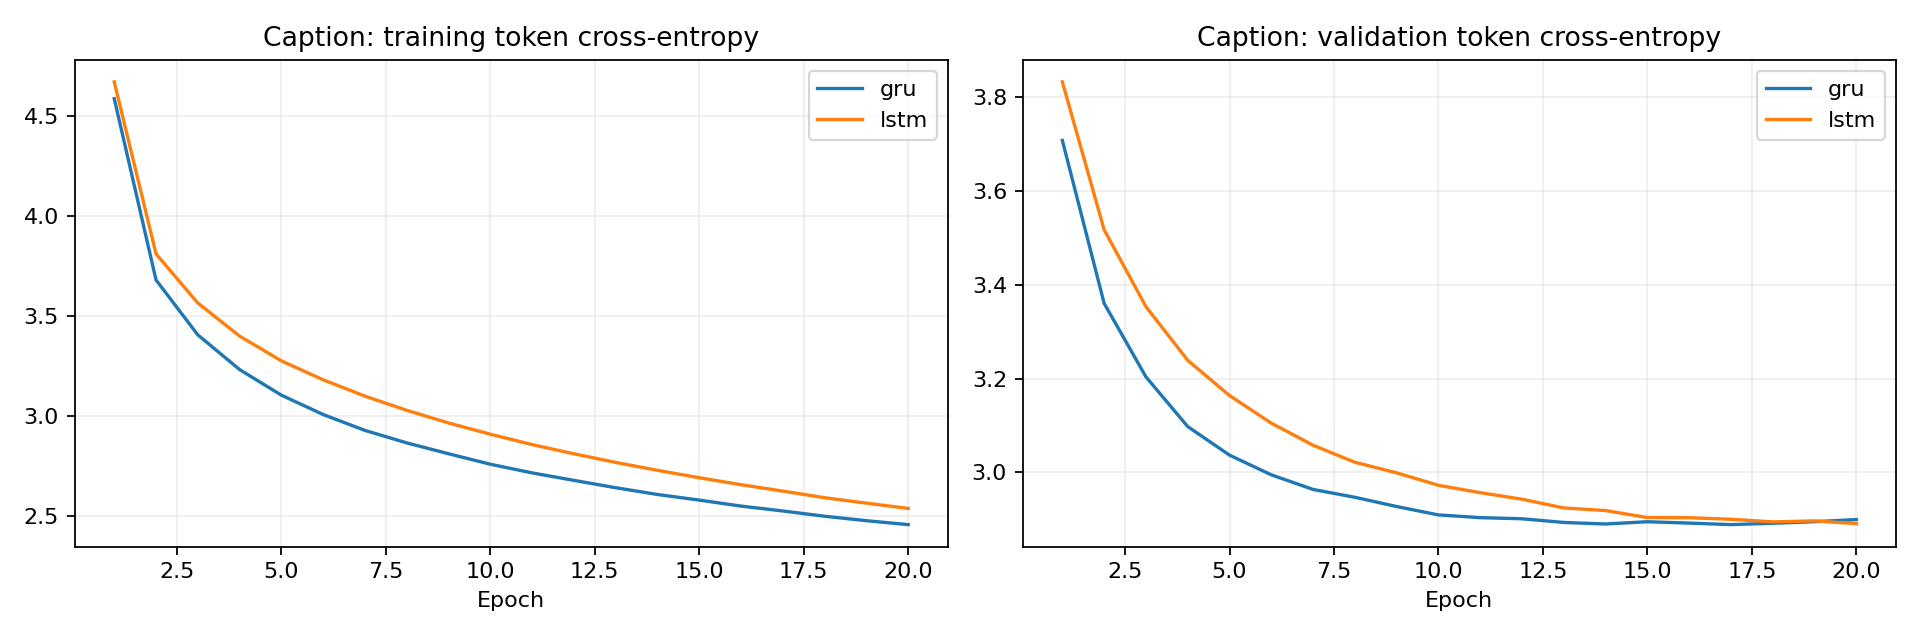

In [2]:
source=Path('models.py').read_text(encoding='utf-8')
display(Markdown('```python\n'+source[source.index('class CaptionModel'):source.index('def make_vision')]+'```'))
show('caption_learning.png')

重新訓練與生成入口：`python quiz4_caption.py`；新圖片推論：`python predict.py caption image.jpg --model lstm`（需 checkpoints）。

## test 生成、BLEU 與計時

BLEU-1/4 由 test 全部影像的所有參考句計算，為 corpus 分數（0–1），含 brevity penalty、不 smoothing。計時同一組 100 張、batch=1、暖機與 CUDA 同步，包含前處理 + encoder + decoder，排除磁碟讀圖及網路。

,model,best_epoch,train_seconds,feature_extraction_seconds,decoder_parameters,test_images,bleu1,bleu4,mean_ms,median_ms,p95_ms,timing_samples,mean_caption_tokens
0,ResNet18 + GRU,17,96.405735,49.193117,3604080,1091,0.537270,0.144649,12.787172,12.316052,17.913265,100,10.476627
1,ResNet18 + LSTM,20,101.105777,49.193117,3866992,1091,0.508075,0.133642,13.683750,12.722593,22.816221,100,11.237397


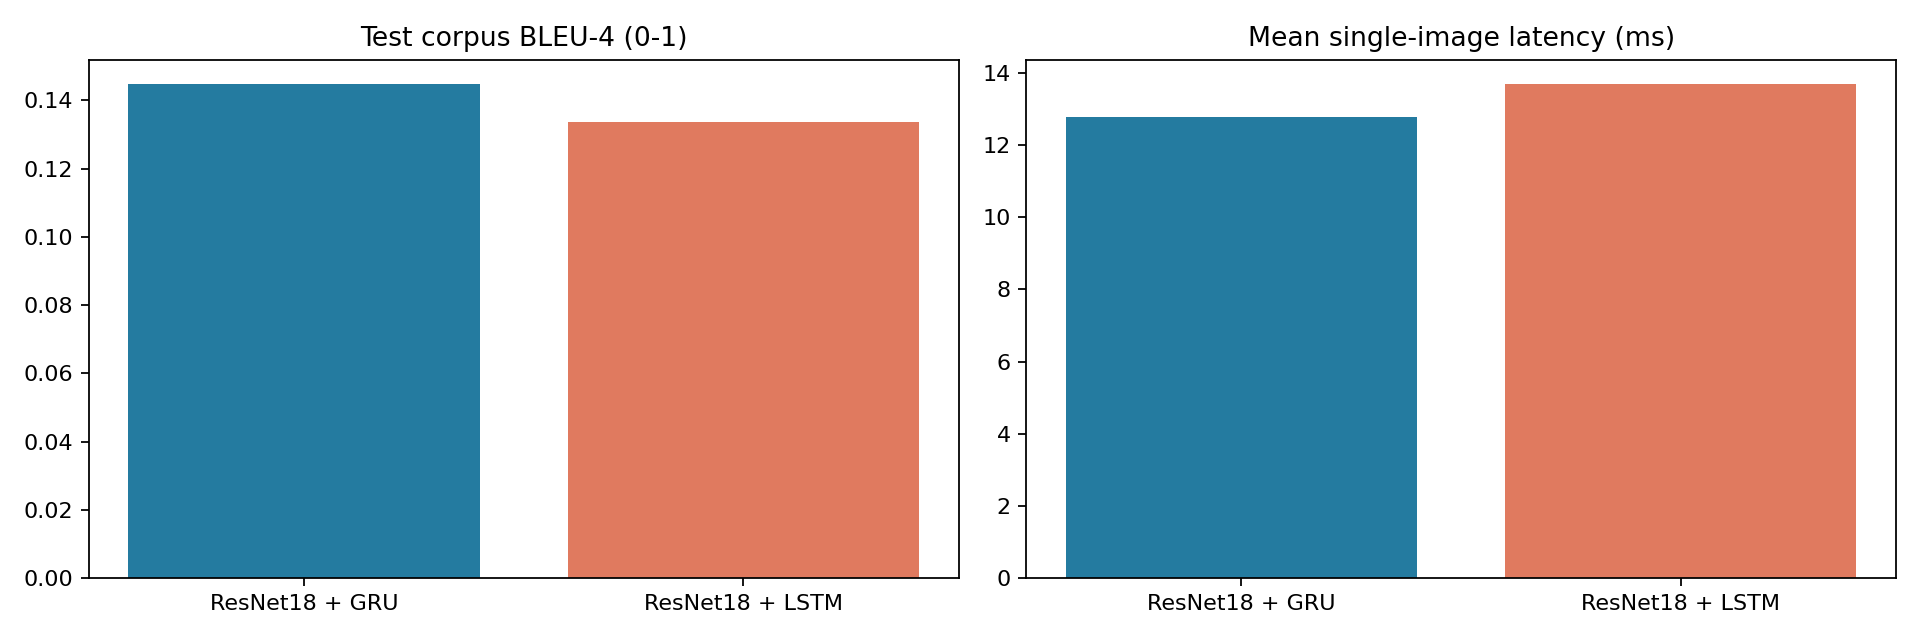

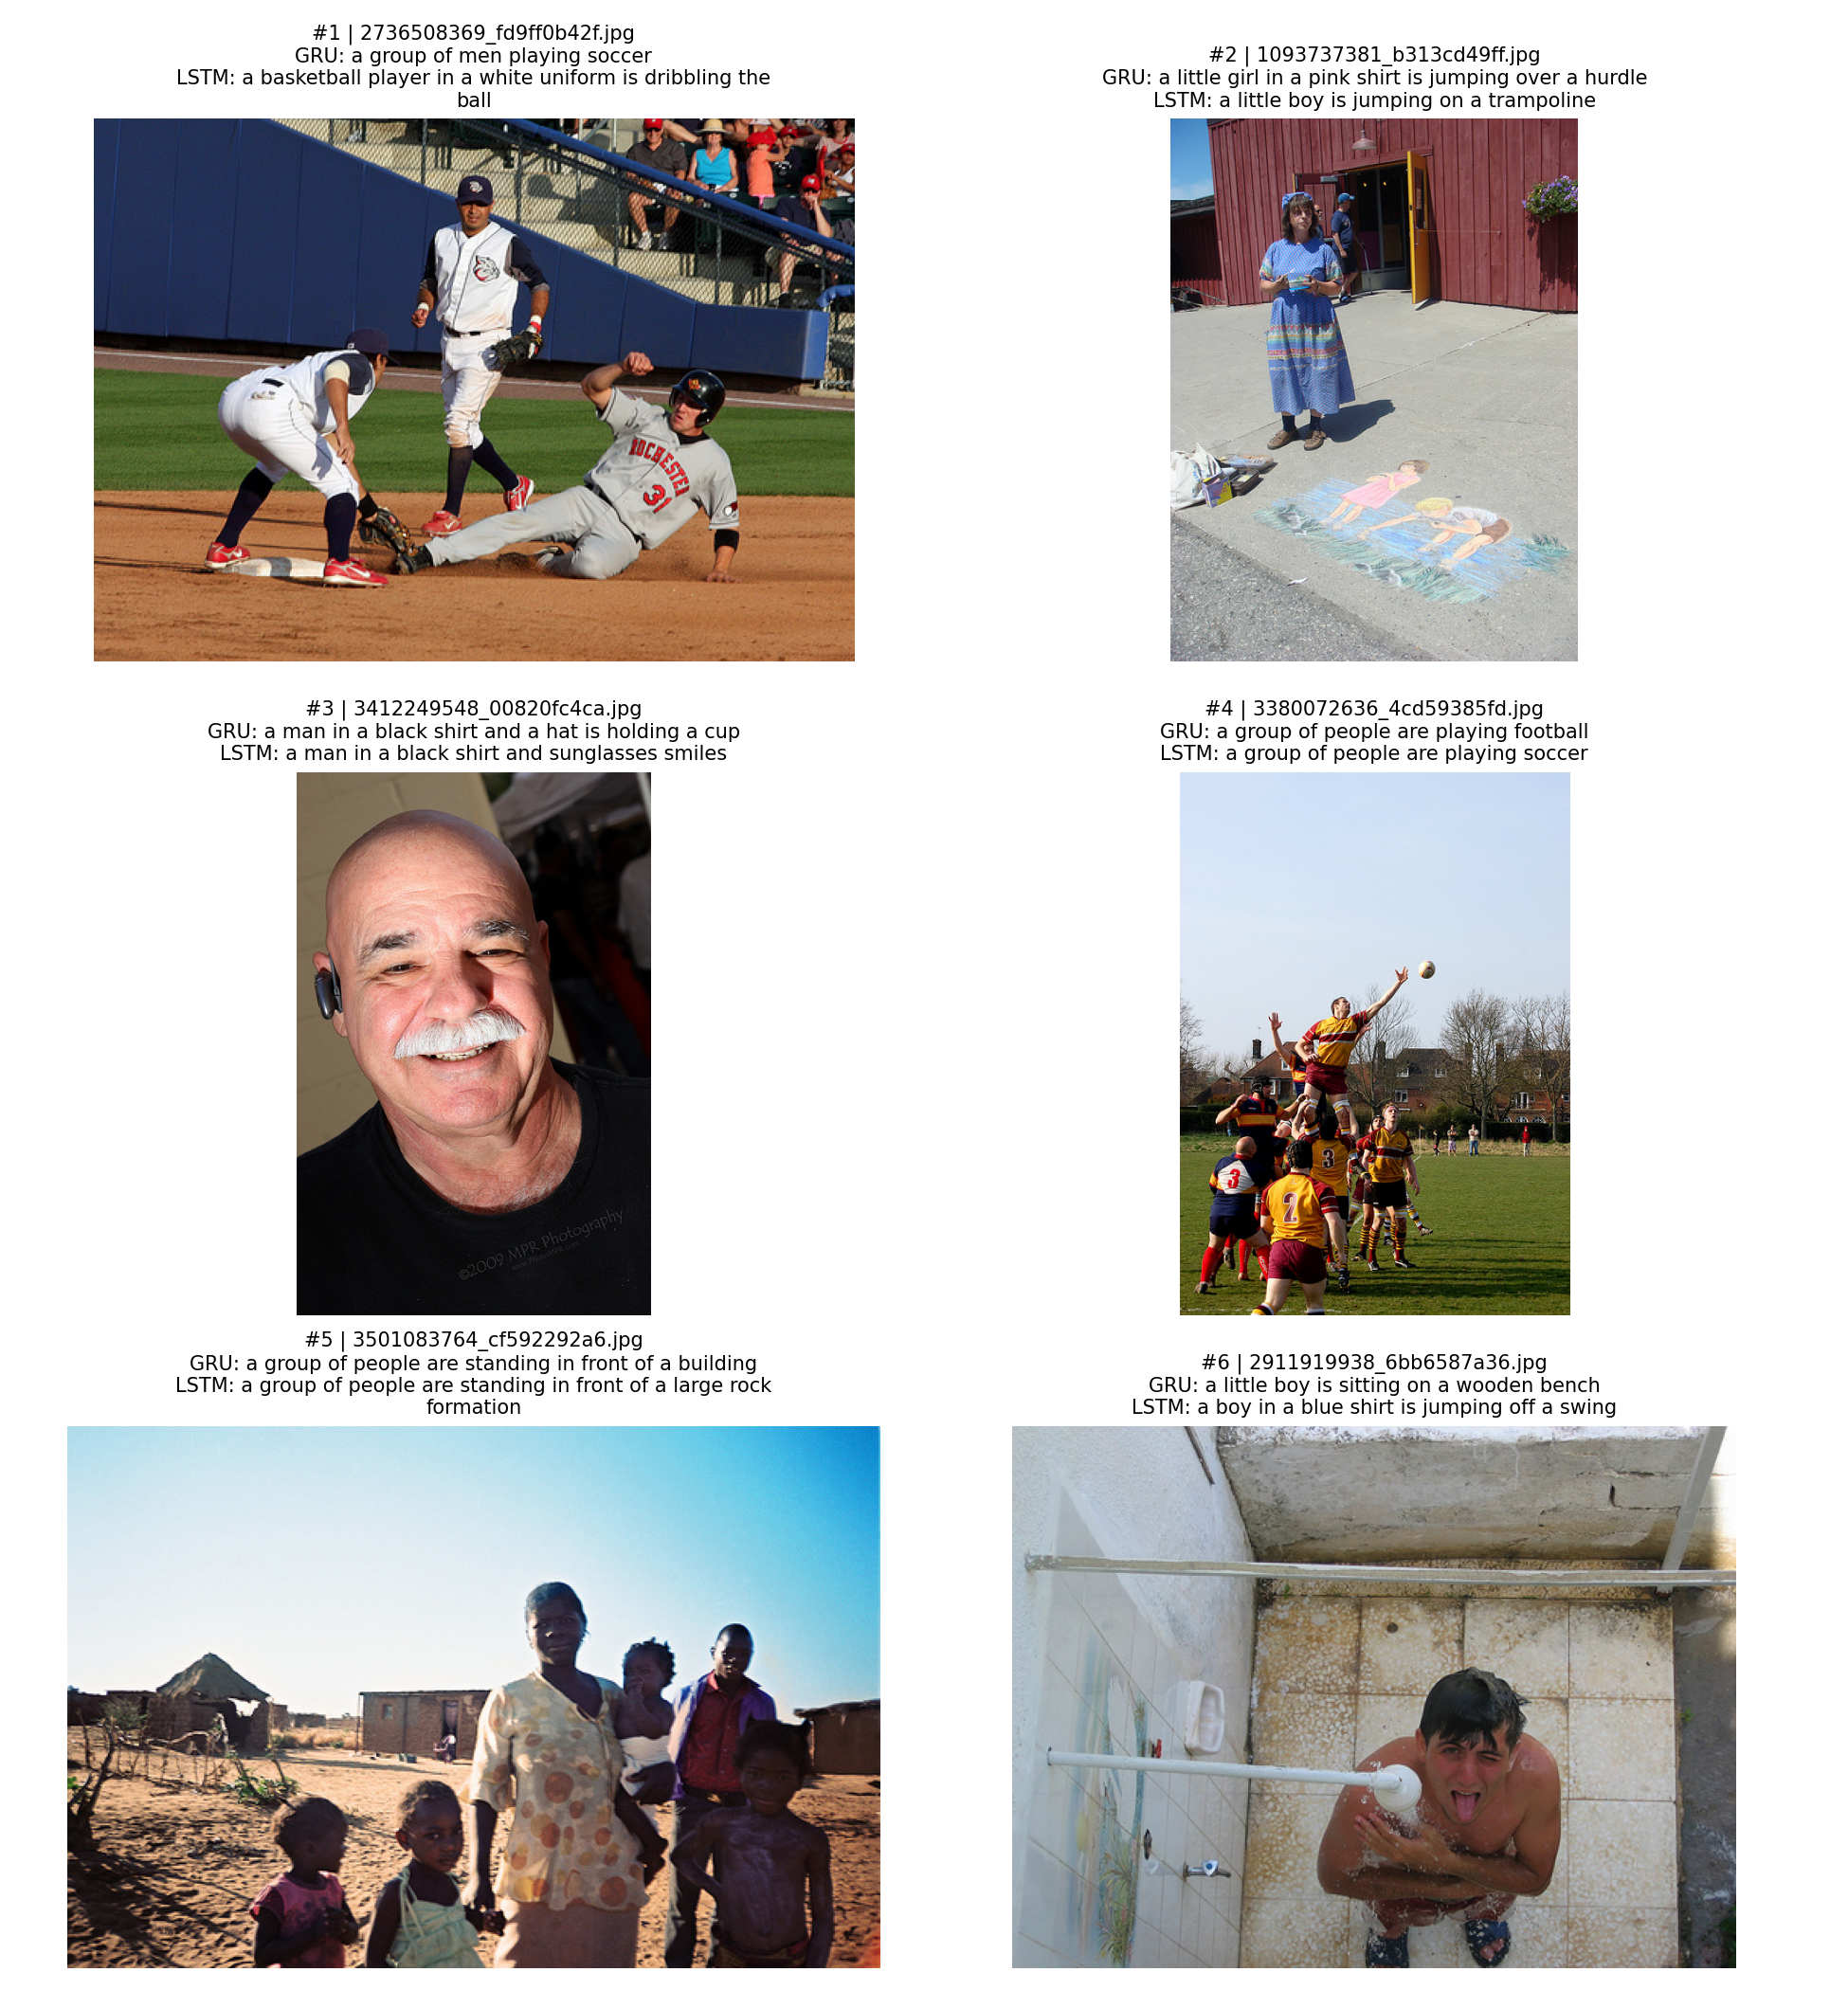

,source_id,filename,generated,references
0,2800,2736508369_fd9ff0b42f.jpg,a basketball player in a white uniform is drib...,[A baseball player is tagged out sliding into ...
1,79,1093737381_b313cd49ff.jpg,a little boy is jumping on a trampoline,[A woman in a blue dress stands with a chalk p...
2,5490,3412249548_00820fc4ca.jpg,a man in a black shirt and sunglasses smiles,[A bald man with an earpiece is smiling nearby...
3,5359,3380072636_4cd59385fd.jpg,a group of people are playing soccer,[A group of men are playing rugby in a field w...
4,5961,3501083764_cf592292a6.jpg,a group of people are standing in front of a l...,[A black mother and five children in a rural a...
5,3357,2911919938_6bb6587a36.jpg,a boy in a blue shirt is jumping off a swing,"[A boy getting a shower, A man is taking a sho..."


In [3]:
display(pd.read_csv(R/'caption_metrics.csv'))
show('caption_comparison.png')
show('caption_examples.png')
display(pd.DataFrame(read('predictions/caption_lstm.json')).head(6))

## Gemini 實際評審

固定前六張 test 影像，模型 A/B 盲評，附原始提示、回覆與截圖。小樣本僅作質性分析，不能視為整個測試集的準確率。

In [4]:
review=R/'gemini_review/review.md'
display(Markdown(review.read_text(encoding='utf-8') if review.exists() else 'Gemini 評審尚未完成。'))

評審日期：2026-10-12。使用 **Google Gemini 網頁版 Flash 模式**；介面未顯示底層模型版本，因此不另推定版本。已實際上傳固定 test 前六張圖片與兩個模型的生成句，沒有提供參考描述。奇數案例 A=GRU、B=LSTM；偶數案例相反，提示中不揭露模型身分。

下表判定及理由保留 Gemini 原意，只移除網頁的 `JPG` 引用按鈕文字；另外加上對照模型與原始 caption。未修改任何不符合結果。

|   case | candidate   | model   | caption                                                           | verdict   | reason                                                                                                              |
|-------:|:------------|:--------|:------------------------------------------------------------------|:----------|:--------------------------------------------------------------------------------------------------------------------|
|      1 | A           | gru     | a group of men playing soccer                                     | 不符合    | 畫面中是一群穿著棒球服的男子在棒球場進行滑壘與守備，並非在踢足球（playing soccer）。                                |
|      1 | B           | lstm    | a basketball player in a white uniform is dribbling the ball      | 不符合    | 畫面中為棒球比賽的滑壘場景，既非籃球選手（basketball player），也沒有運球（dribbling the ball）的動作。             |
|      2 | A           | lstm    | a little boy is jumping on a trampoline                           | 不符合    | 圖片主要主體為一名站立的成年女性以及地上的粉筆畫，完全沒有小男孩在彈跳床跳躍（jumping on a trampoline）的實體場景。 |
|      2 | B           | gru     | a little girl in a pink shirt is jumping over a hurdle            | 不符合    | 地面彩繪雖繪有粉色衣著的小孩，但並非真實小女孩，亦無跨欄（jumping over a hurdle）的動作或設施。                     |
|      3 | A           | gru     | a man in a black shirt and a hat is holding a cup                 | 部分符合  | 圖片支持光頭男子身穿黑衣且帶有微笑，但他並未配戴帽子（hat）亦無手持杯子（holding a cup）。                          |
|      3 | B           | lstm    | a man in a black shirt and sunglasses smiles                      | 部分符合  | 圖片支持該名身穿黑衣的男子正面微笑，但他配戴的是耳掛式耳機而非太陽眼鏡（sunglasses）。                              |
|      4 | A           | lstm    | a group of people are playing soccer                              | 不符合    | 畫面呈現的是英式橄欖球（rugby）爭球或拋球場景，並非進行英式足球（playing soccer）運動。                             |
|      4 | B           | gru     | a group of people are playing football                            | 符合      | 畫面中一群男子正在草地上進行橄欖球（football/rugby）比賽，主要人物、數量、運動情境與空間關係皆能由圖片支持。        |
|      5 | A           | gru     | a group of people are standing in front of a building             | 符合      | 圖片支持畫面中央與右側有一群人（婦女與孩童）站立於戶外，背景確實為平房建物（building）。                            |
|      5 | B           | lstm    | a group of people are standing in front of a large rock formation | 不符合    | 畫面支持有一群人站立在沙地上，但背景為數間磚瓦平房與茅草屋，並不存在大型岩石地形（large rock formation）。          |
|      6 | A           | lstm    | a boy in a blue shirt is jumping off a swing                      | 不符合    | 畫面為一名赤膊青年在室外蓮蓬頭下沖水淋浴，既非身穿藍衣，也沒有從鞦韆上跳下（jumping off a swing）。                 |
|      6 | B           | gru     | a little boy is sitting on a wooden bench                         | 不符合    | 主體為一名站立仰頭沖澡的青年，並非坐在木質長椅（sitting on a wooden bench）上的小男孩。                             |

抽樣判定筆數（每模型 6 筆）：

| model   |   符合 |   部分符合 |   不符合 |
|:--------|-------:|-----------:|---------:|
| gru     |      2 |          1 |        3 |
| lstm    |      0 |          1 |        5 |

GRU 在這六張中有兩筆「符合」，LSTM 沒有完整符合案例；兩者各有一筆「部分符合」。這與本次 GRU 的 BLEU-4 較高方向一致，但 **六張質性抽樣不能估計全測試集準確率，也不足以證明架構優劣**。兩個模型都有把棒球、淋浴等核心事件說錯的案例，顯示能生成流暢句子不代表影像語意正確。

**評審歧義與限制：** 案例 4 的圖片是 rugby。Gemini 將 GRU 的 `football` 視為涵蓋 rugby 而判「符合」；若把 `football` 狹義解讀為美式足球或 association football，評價可能較低。因此保留原判定，同時指出此處有語詞歧義。模型與 Gemini 的細節判斷都可能出錯，不能以評審文字取代圖片證據。

查核檔案位於 `results/gemini_review/`：`prompt.txt` 為送出的提示；`raw_response.txt` 為可見回覆的原始文字（含網頁引用標籤）；`raw_rows.json` 保存原始表格欄位；`review.csv` 是 A/B 映射後的表格；`metadata.json` 記錄模式及原對話；`gemini_review_start.png` 與 `gemini_review.png` 保存網頁畫面。六張原圖與生成描述見上方例圖及 `results/gemini_cases.json`。


## 可重算驗證

In [5]:
import subprocess, sys
subprocess.run([sys.executable,'verify_results.py'],check=True)
display(read('verification.json'))

{'passed': True,
 'checks': ['sentiment split separation',
  'vision split separation',
  'caption split separation',
  'sentiment metrics and paired test IDs',
  'vision metrics and paired test IDs',
  'caption BLEU and paired test IDs',
  'latency measured samples',
  'nonempty generated captions',
  'both pretrained backbones really updated']}